<div style="color:#3c4d5a; border-top: 7px solid #42A5F5; border-bottom: 7px solid #42A5F5; padding: 10px; text-align: center; text-transform: uppercase">
    <h1>Práctica 2: Desarrollo y Optimización de Clasificador SVM con Pipeline para Aprobación de Créditos</h1>
    <h3>Uso de Pipeline, ColumnTransformer, cross_val_score, métricas, GridSearchCV, Visualización en Heatmap y Explicabilidad de Predicciones</h3>
</div>

**Asignatura:** Aprendizaje Automático  
**Docente:** Ing. Remigio Hurtado Ortiz, PhD.  
**Dataset:** Statlog (German Credit Data) - UCI Machine Learning Repository  
**Objetivo:** Desarrollar, evaluar, optimizar y explicar un modelo de clasificación basado en Máquinas de Soporte Vectorial (SVM) mediante Pipelines integrados de preprocesamiento y ajuste fino de hiperparámetros.

### Tabla de Contenidos:
1. [Fundamentos Teóricos: Machine Learning y SVM](#Fundamentos)
2. [Importación de Librerías y Entorno](#Importacion)
3. [Carga y Exploración del Dataset (German Credit Data)](#Carga-descripcion)
4. [Construcción y Persistencia del Pipeline de Preprocesamiento](#CargarPipeline)
5. [Integración del Clasificador SVM en el Pipeline](#Creacion)
6. [Entrenamiento y Evaluación del Modelo Base](#EntrenamientoBase)
7. [Evaluación con Métricas de Rendimiento (Accuracy, Precision, Recall, F1, Matriz de Confusión)](#EvaluacionMetricas)
8. [Validación Cruzada con `cross_val_score`](#EvaluacionCVS)
9. [Optimización de Hiperparámetros con `GridSearchCV`](#OptimizacionGridSearchCV)
10. [Visualización de Resultados de Optimización con Heatmap](#Visualizacion)
11. [Creación y Evaluación del Modelo Optimizado](#CreacionModeloOptimizado)
12. [Función de Inferencia para Nuevos Clientes (`predecirNuevoCliente`)](#PrediccionNuevoElemento)
13. [Justificación y Explicabilidad de Predicciones (Importancia de Características)](#Explicabilidad)
14. [Conclusiones y Discusión](#Conclusiones)
15. [Referencias en Formato APA](#Referencias)

<div id="Fundamentos" style="color:#37475a; border-bottom: 5px solid orange; width: 100%; margin-bottom: 15px; padding-bottom: 2px">
    <h2>1. Fundamentos Teóricos: Machine Learning y SVM</h2>
</div>

El **Aprendizaje Supervisado** se enfoca en inducir una función predictiva a partir de pares de entrenamiento $(X, y)$, distinguiéndose fundamentalmente problemas de **regresión** (cuando la salida $y$ es continua) y **clasificación** (cuando $y$ pertenece a un conjunto discreto de categorías o clases).

### Máquinas de Soporte Vectorial (SVM - Support Vector Machines)
Las SVM son modelos basados en el principio de **Minimización del Riesgo Estructural**. Para clasificación binaria linealmente separable, el objetivo es encontrar el hiperplano óptimo de decisión que maximice el margen de separación entre las clases más cercanas:

$$\max_{\mathbf{w}, b} \frac{2}{\|\mathbf{w}\|} \quad \text{sujeto a} \quad y_i (\mathbf{w} \cdot \mathbf{x}_i + b) \ge 1, \quad \forall i$$

Los vectores de soporte son aquellos puntos de datos críticos que se sitúan sobre las fronteras del margen y definen la orientación y posición del hiperplano.

#### Parámetros Clave e Hiperparámetros de SVM:
- **Regularización ($C$):** Controla el equilibrio entre maximizar el margen de separación y minimizar el error de clasificación sobre los datos de entrenamiento (penalización por variables de holgura $\xi_i$). Valores altos de $C$ penalizan severamente los errores (riesgo de *overfitting*), mientras que valores bajos permiten márgenes más amplios y tolerantes a clasificaciones erróneas (mayor capacidad de generalización).
- **Truco del Kernel (*Kernel Trick*):** Permite proyectar implícitamente los datos de entrada a un espacio de características de mayor dimensión $\Phi(\mathbf{x})$ donde las clases no separables linealmente se vuelven separables, sin necesidad de calcular explícitamente las coordenadas en dicho espacio:
  - **Lineal:** $K(\mathbf{x}, \mathbf{x}') = \mathbf{x}^T \mathbf{x}'$
  - **Polinomial (`poly`):** $K(\mathbf{x}, \mathbf{x}') = (\gamma \mathbf{x}^T \mathbf{x}' + r)^d$
  - **RBF (Gaussiano - `rbf`):** $K(\mathbf{x}, \mathbf{x}') = \exp(-\gamma \|\mathbf{x} - \mathbf{x}'\|^2)$
  - **Sigmoidal (`sigmoid`):** $K(\mathbf{x}, \mathbf{x}') = \tanh(\gamma \mathbf{x}^T \mathbf{x}' + r)$
- **Coeficiente $\gamma$ (`gamma`):** Determina el radio de influencia de las muestras individuales de entrenamiento en kernels no lineales. Valores elevados implican radios pequeños (fronteras más complejas y ajustadas); valores pequeños generalizan sobre regiones más amplias.

<div id="Importacion" style="color:#106ba3">
    <h2>2. Importación de Librerías y Entorno</h2>
</div>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pickle
import copy
import os
from time import time
from datetime import datetime, timedelta

# Preprocesamiento y composición de Pipelines
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, OrdinalEncoder, MinMaxScaler
from sklearn.compose import ColumnTransformer, make_column_transformer
from sklearn.pipeline import Pipeline

# Modelos, Selección y Validación
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split, cross_val_score, ShuffleSplit, GridSearchCV
from sklearn.inspection import permutation_importance

# Métricas de Evaluación
from sklearn import metrics
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, classification_report

# Configuración visual
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
%matplotlib inline

print("Todas las librerías y dependencias han sido cargadas exitosamente.")

Todas las librerías y dependencias han sido cargadas exitosamente.


<div id="Carga-descripcion" style="color:#106ba3">
    <h2>3. Carga y Exploración del Dataset (Statlog German Credit Data)</h2>
</div>

* **Fuente:** UCI Machine Learning Repository (Statlog German Credit Data).
* **Muestras:** 1000 instancias (solicitantes de crédito bancario).
* **Variables:** 20 atributos predictivos (financieros, laborales, personales y de historial crediticio).
* **Variable Objetivo (`TIPOCLIENTE`):**
  - Original: `1` = Buen Pagador (Bajo Riesgo), `2` = Mal Pagador (Alto Riesgo).
  - Transformada: `1` = Crédito Aprobado (Bajo Riesgo), `0` = Crédito Rechazado / No Aprobado (Alto Riesgo).

In [2]:
# Definición oficial de nombres de variables en el dataset German Credit
nombresVariables = [
    'ESTADOCUENTACORRIENTE', 'PLAZOMESESCREDITO', 'HISTORIALCREDITO', 'PROPOSITOCREDITO', 'MONTOCREDITO',
    'SALDOCUENTAAHORROS', 'TIEMPOACTUALEMPLEO', 'TASAPAGO', 'ESTADOCIVILYSEXO', 'GARANTE', 'TIEMPORESIDENCIAACTUAL',
    'ACTIVOS', 'EDAD', 'OTROSPLANESPAGO', 'VIVIENDA', 'CANTIDADCREDITOSEXISTENTES', 'EMPLEO',
    'CANTIDADPERSONASAMANTENER', 'TELEFONO', 'TRABAJADOREXTRANJERO', 'TIPOCLIENTE'
]

# Carga con respaldo local o remoto desde UCI Repository
archivo_local = 'german.data'
url_remota = 'http://archive.ics.uci.edu/ml/machine-learning-databases/statlog/german/german.data'

if os.path.exists(archivo_local):
    print(f"Cargando dataset desde copia local: {archivo_local}")
    dfOriginal = pd.read_csv(archivo_local, sep=' ', names=nombresVariables)
else:
    print(f"Descargando dataset desde URL remota: {url_remota}")
    dfOriginal = pd.read_csv(url_remota, sep=' ', names=nombresVariables)

dataframe = copy.deepcopy(dfOriginal)
print(f"Dimensiones del dataset cargado: {dataframe.shape}")
dataframe.head()

Descargando dataset desde URL remota: http://archive.ics.uci.edu/ml/machine-learning-databases/statlog/german/german.data


Dimensiones del dataset cargado: (1000, 21)


,ESTADOCUENTACORRIENTE,PLAZOMESESCREDITO,HISTORIALCREDITO,PROPOSITOCREDITO,MONTOCREDITO,SALDOCUENTAAHORROS,TIEMPOACTUALEMPLEO,TASAPAGO,ESTADOCIVILYSEXO,GARANTE,...,ACTIVOS,EDAD,OTROSPLANESPAGO,VIVIENDA,CANTIDADCREDITOSEXISTENTES,EMPLEO,CANTIDADPERSONASAMANTENER,TELEFONO,TRABAJADOREXTRANJERO,TIPOCLIENTE
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,...,A121,67,A143,A152,2,A173,1,A192,A201,1
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,...,A121,22,A143,A152,1,A173,1,A191,A201,2
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,...,A121,49,A143,A152,1,A172,2,A191,A201,1
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,...,A122,45,A143,A153,1,A173,2,A191,A201,1
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,...,A124,53,A143,A153,2,A173,2,A191,A201,2


In [3]:
# Extracción de la variable objetivo
Y = dataframe['TIPOCLIENTE'].copy()

# Eliminación de atributos no predictivos según el diseño metodológico
dataframe = dataframe.drop(['OTROSPLANESPAGO', 'TELEFONO', 'TIPOCLIENTE'], axis=1)
dataframePreprocesado = copy.deepcopy(dataframe)

# Transformación de la variable objetivo a binaria (1: Aprobado / Buen cliente, 0: Denegado / Mal cliente)
Y[Y == 1] = 1
Y[Y == 2] = 0

print("Distribución de clases de la variable objetivo:")
print(Y.value_counts(normalize=True).rename(index={1: 'Bueno (1)', 0: 'Malo (0)'}))
print(f"\nDimensiones de la matriz de características X: {dataframe.shape}")

Distribución de clases de la variable objetivo:
TIPOCLIENTE
Bueno (1)    0.7
Malo (0)     0.3
Name: proportion, dtype: float64

Dimensiones de la matriz de características X: (1000, 18)


<div id="CargarPipeline" style="color:#37475a; border-bottom: 5px solid orange; width: 100%; margin-bottom: 15px; padding-bottom: 2px">
    <h2>4. Construcción y Persistencia del Pipeline de Preprocesamiento</h2>
</div>

Para garantizar un flujo modular, reproducible y libre de fuga de datos (*data leakage*), construimos un `Pipeline` compuesto de preprocesamiento estructurado en:
1. **`prepcn` (Transformador Categórico Mixto):**
   - Variables ordinales procesadas con `OrdinalEncoder`.
   - Variables nominales codificadas con `OneHotEncoder(handle_unknown='ignore', sparse_output=False)`.
2. **`prepminmax`:** Escalado con `MinMaxScaler(feature_range=(0, 1))`.
3. **`prepsimpleimputer`:** Imputación de valores faltantes con `SimpleImputer(strategy='median')`.
4. **`prepstandard`:** Estandarización de variables con `StandardScaler(with_mean=True, with_std=True)`.

In [4]:
# Funciones para serialización y persistencia de Pipelines y Modelos
def guardarPipeline(pipeline, nombreArchivo):
    with open(nombreArchivo + '.pickle', 'wb') as handle:
        pickle.dump(pipeline, handle, protocol=pickle.HIGHEST_PROTOCOL)
    print(f"Pipeline guardado exitosamente en '{nombreArchivo}.pickle'")

def cargarPipeline(nombreArchivo):
    with open(nombreArchivo + '.pickle', 'rb') as handle:
        pipeline = pickle.load(handle)
    print(f"Pipeline cargado exitosamente desde '{nombreArchivo}.pickle'")
    return pipeline

# Clasificación de características
categorical_ordinal_features = [
    'ESTADOCUENTACORRIENTE', 'HISTORIALCREDITO', 'SALDOCUENTAAHORROS', 'TIEMPOACTUALEMPLEO',
    'ESTADOCIVILYSEXO', 'ACTIVOS', 'VIVIENDA', 'EMPLEO'
]
categorical_nominal_features = ['PROPOSITOCREDITO', 'GARANTE', 'TRABAJADOREXTRANJERO']
numeric_features = [
    'PLAZOMESESCREDITO', 'MONTOCREDITO', 'TASAPAGO', 'TIEMPORESIDENCIAACTUAL',
    'EDAD', 'CANTIDADCREDITOSEXISTENTES', 'CANTIDADPERSONASAMANTENER'
]

# Cálculo de variables resultantes tras One-Hot Encoding
cantidadTotalVariables = len(dataframe.columns)
cantidadVariablesBinarias = sum(dataframe[col].nunique() for col in categorical_nominal_features)
cantidadTotalVariablesConTransformacion = cantidadTotalVariables - len(categorical_nominal_features) + cantidadVariablesBinarias
print(f"Cantidad de variables iniciales: {cantidadTotalVariables}")
print(f"Cantidad total de variables tras codificación One-Hot: {cantidadTotalVariablesConTransformacion}")

# 1. Definición de preprocesadores de características
cat_ord_transformer = Pipeline(steps=[('ordinal', OrdinalEncoder())])
cat_nom_transformer = Pipeline(steps=[('onehot', OneHotEncoder(sparse_output=False, handle_unknown='ignore'))])

preprocesorCategoricoNumerico = ColumnTransformer(
    transformers=[
        ('catord', cat_ord_transformer, categorical_ordinal_features),
        ('catnom', cat_nom_transformer, categorical_nominal_features)
    ], remainder='passthrough')

# 2. MinMaxScaler
minmax_transformer = Pipeline(steps=[('minmax', MinMaxScaler(feature_range=(0, 1)))])
preprocesorMinMax = ColumnTransformer(transformers=[
    ('tranminmax', minmax_transformer, list(range(cantidadTotalVariablesConTransformacion)))
], remainder='passthrough')

# 3. SimpleImputer
simpleimputer_transformer = Pipeline(steps=[('simpleimputer', SimpleImputer(strategy='median'))])
preprocesorSimpleImputer = ColumnTransformer(transformers=[
    ('transimpleimputer', simpleimputer_transformer, list(range(cantidadTotalVariablesConTransformacion)))
], remainder='passthrough')

# 4. StandardScaler
standardscaler_transformer = Pipeline(steps=[('scaler', StandardScaler(with_mean=True, with_std=True))])
preprocesorStandardScaler = ColumnTransformer(transformers=[
    ('transcaler', standardscaler_transformer, list(range(cantidadTotalVariablesConTransformacion)))
], remainder='passthrough')

# Ensamblado del Pipeline de preprocesamiento
pipe_preprocesamiento = Pipeline(steps=[
    ('prepcn', preprocesorCategoricoNumerico),
    ('prepminmax', preprocesorMinMax),
    ('prepsimpleimputer', preprocesorSimpleImputer),
    ('prepstandard', preprocesorStandardScaler)
])

# Guardar y validar recarga
guardarPipeline(pipe_preprocesamiento, 'pipeFullPreprocesadores')
pipe = cargarPipeline('pipeFullPreprocesadores')
cantidadPasos = len(pipe.steps)
print(f"Pasos activos en el pipeline: {cantidadPasos}")
for idx, (nombre, step) in enumerate(pipe.steps):
    print(f"  Paso {idx}: {nombre} -> {step.__class__.__name__}")

Cantidad de variables iniciales: 18
Cantidad total de variables tras codificación One-Hot: 30
Pipeline guardado exitosamente en 'pipeFullPreprocesadores.pickle'
Pipeline cargado exitosamente desde 'pipeFullPreprocesadores.pickle'
Pasos activos en el pipeline: 4
  Paso 0: prepcn -> ColumnTransformer
  Paso 1: prepminmax -> ColumnTransformer
  Paso 2: prepsimpleimputer -> ColumnTransformer
  Paso 3: prepstandard -> ColumnTransformer


<div id="Creacion" style="color:#37475a; border-bottom: 5px solid orange; width: 100%; margin-bottom: 15px; padding-bottom: 2px">
    <h2>5. Integración del Clasificador SVM en el Pipeline</h2>
</div>

Instanciamos un clasificador SVM base con:
* `kernel='poly'`
* `gamma=0.1`
* `C=1.0`
* `random_state=0`

Añadimos el clasificador al final del pipeline dinámicamente mediante `pipe.steps.insert()`.

In [5]:
# Ajustamos el transformador previo y agregamos la SVM al pipeline
pipe.fit_transform(dataframePreprocesado)

# Inserción del estimador al final del Pipeline
pipe.steps.insert(cantidadPasos, ['modelSVM', SVC(gamma=0.1, kernel='poly', C=1.0, random_state=0, verbose=False)])

print(f"Cantidad total de pasos del pipeline integrado: {len(pipe.steps)}")
print(f"Último paso integrado: {pipe.steps[-1]}")

Cantidad total de pasos del pipeline integrado: 5
Último paso integrado: ['modelSVM', SVC(gamma=0.1, kernel='poly', random_state=0)]


<div id="EntrenamientoBase" style="color:#106ba3">
    <h2>6. Entrenamiento y Predicción con el Modelo Base</h2>
</div>

Efectuamos la partición en entrenamiento y prueba (80% / 20%) con `random_state=0` y entrenamos el estimador compuesto.

In [6]:
train = copy.deepcopy(dataframe)
test = copy.deepcopy(Y)

X_train, X_test, y_train, y_test = train_test_split(train, test, test_size=0.2, random_state=0, stratify=test)

# Ajuste del modelo compuesto
pipe.fit(X_train, y_train)

# Predicciones sobre el conjunto de prueba
y_pred = pipe.predict(X_test)

dataframeComparativa = pd.DataFrame({'Real': y_test.values, 'Predicción': y_pred})
print("Primeras 10 predicciones vs valores reales:")
dataframeComparativa.head(10)

Primeras 10 predicciones vs valores reales:


,Real,Predicción
0,1,1
1,1,1
2,1,0
3,1,0
4,0,0
5,1,0
6,1,1
7,0,1
8,1,1
9,1,1


<div id="EvaluacionMetricas" style="color:#37475a; border-bottom: 5px solid orange; width: 100%; margin-bottom: 15px; padding-bottom: 2px">
    <h2>7. Evaluación con Métricas de Rendimiento</h2>
</div>

Calculamos las métricas fundamentales para clasificación:
* **MAE, MSE y RMSE**
* **Accuracy (Exactitud)**
* **Precision, Recall y F1-Score**
* **Matriz de Confusión**

     MÉTRICAS DEL MODELO SVM BASE
Mean Absolute Error (MAE):       0.3000
Mean Squared Error (MSE):        0.3000
Root Mean Squared Error (RMSE):  0.5477
Accuracy (Exactitud):            0.7000 (70.00%)
Precision:                       0.7740
Recall (Sensibilidad):           0.8071
F1-Score:                        0.7902


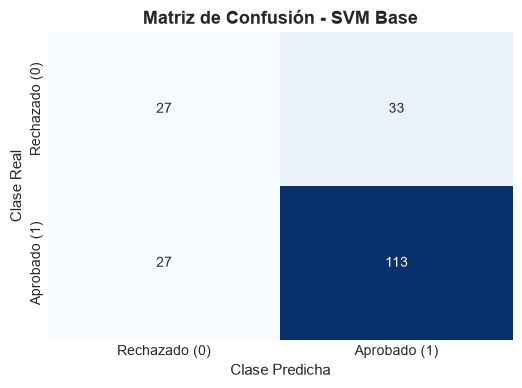

Verdaderos Negativos (TN): 27 | Falsos Positivos (FP): 33
Falsos Negativos (FN):     27 | Verdaderos Positivos (TP): 113


In [7]:
mae = metrics.mean_absolute_error(y_test, y_pred)
mse = metrics.mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("=" * 45)
print("     MÉTRICAS DEL MODELO SVM BASE")
print("=" * 45)
print(f"Mean Absolute Error (MAE):       {mae:.4f}")
print(f"Mean Squared Error (MSE):        {mse:.4f}")
print(f"Root Mean Squared Error (RMSE):  {rmse:.4f}")
print(f"Accuracy (Exactitud):            {acc:.4f} ({acc*100:.2f}%)")
print(f"Precision:                       {prec:.4f}")
print(f"Recall (Sensibilidad):           {rec:.4f}")
print(f"F1-Score:                        {f1:.4f}")
print("=" * 45)

# Matriz de Confusión
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

fig, ax = plt.subplots(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
            xticklabels=['Rechazado (0)', 'Aprobado (1)'],
            yticklabels=['Rechazado (0)', 'Aprobado (1)'])
ax.set_title('Matriz de Confusión - SVM Base', fontsize=13, fontweight='bold')
ax.set_xlabel('Clase Predicha', fontsize=11)
ax.set_ylabel('Clase Real', fontsize=11)
plt.show()

print(f"Verdaderos Negativos (TN): {tn} | Falsos Positivos (FP): {fp}")
print(f"Falsos Negativos (FN):     {fn} | Verdaderos Positivos (TP): {tp}")

<div id="EvaluacionCVS" style="color:#37475a; border-bottom: 5px solid orange; width: 100%; margin-bottom: 15px; padding-bottom: 2px">
    <h2>8. Validación Cruzada con `cross_val_score`</h2>
</div>

Realizamos una validación cruzada con 5 particiones aleatorias estratificadas (`ShuffleSplit`) para evaluar la estabilidad del rendimiento del modelo base.

In [8]:
sd = 0
numFolds = 5
kfold = ShuffleSplit(n_splits=numFolds, test_size=0.2, random_state=sd)

cv_scores = cross_val_score(pipe, train, test, cv=kfold, n_jobs=-1)

print("Accuracy por cada partición (Fold):")
for i, score in enumerate(cv_scores, 1):
    print(f"  Fold {i}: {score:.4f} ({score*100:.2f}%)")

print("-" * 35)
print(f"Media de Accuracy (CV): {cv_scores.mean():.4f} +/- {cv_scores.std():.4f}")

Accuracy por cada partición (Fold):
  Fold 1: 0.7100 (71.00%)
  Fold 2: 0.7000 (70.00%)
  Fold 3: 0.7250 (72.50%)
  Fold 4: 0.7050 (70.50%)
  Fold 5: 0.7100 (71.00%)
-----------------------------------
Media de Accuracy (CV): 0.7100 +/- 0.0084


<div id="OptimizacionGridSearchCV" style="color:#37475a; border-bottom: 5px solid orange; width: 100%; margin-bottom: 15px; padding-bottom: 2px">
    <h2>9. Optimización de Hiperparámetros con `GridSearchCV`</h2>
</div>

Para encontrar la configuración óptima del pipeline y la SVM, definimos una grilla de hiperparámetros explorando:
* **SVM:** núcleos (`kernel`), parámetro de regularización ($C$) y coeficiente $\gamma$ (`gamma`).
* **Preprocesamiento:** parámetros de escalado y estandarización.

In [9]:
tic = time()

# Grilla de hiperparámetros para la optimización de la SVM
gamma_values = [0.01, 0.1, 1.0]
kernel_values = ['linear', 'poly', 'rbf', 'sigmoid']
C_values = [0.1, 1.0, 5.0, 10.0, 50.0]

param_grid = {
    'modelSVM__C': C_values,
    'modelSVM__gamma': gamma_values,
    'modelSVM__kernel': kernel_values
}

# (Opcional: Grilla extendida para optimizar también preprocesadores si se desea)
# param_grid_extendido = {
#     'prepminmax__tranminmax__minmax__feature_range': [(0, 1), (-1, 1)],
#     'prepsimpleimputer__transimpleimputer__simpleimputer__strategy': ['mean', 'median'],
#     'prepstandard__transcaler__scaler__with_mean': [True, False],
#     'prepstandard__transcaler__scaler__with_std': [True, False],
#     'modelSVM__gamma': gamma_values,
#     'modelSVM__kernel': kernel_values,
#     'modelSVM__C': C_values
# }

print(f"Total de combinaciones a evaluar: {len(C_values) * len(gamma_values) * len(kernel_values)}")
print(f"Total de ajustes con 5-fold CV: {len(C_values) * len(gamma_values) * len(kernel_values) * 5}")

# Instanciación y ejecución de GridSearchCV
gs = GridSearchCV(estimator=pipe, param_grid=param_grid, cv=5, n_jobs=-1, scoring='accuracy', verbose=1)
gs.fit(X_train, y_train)

gs_time = time() - tic
print(f"\nTiempo total de búsqueda: {gs_time:.2f} segundos")
print(f"Mejor score obtenido en CV: {gs.best_score_:.4f}")
print("\nMejores parámetros encontrados:")
for param, val in gs.best_params_.items():
    print(f"  {param}: {val}")

score_test_gs = gs.score(X_test, y_test)
print(f"\nAccuracy del mejor modelo en conjunto de prueba: {score_test_gs:.4f}")

Total de combinaciones a evaluar: 60
Total de ajustes con 5-fold CV: 300
Fitting 5 folds for each of 60 candidates, totalling 300 fits



Tiempo total de búsqueda: 4.93 segundos
Mejor score obtenido en CV: 0.7538

Mejores parámetros encontrados:
  modelSVM__C: 1.0
  modelSVM__gamma: 0.01
  modelSVM__kernel: linear

Accuracy del mejor modelo en conjunto de prueba: 0.8150


<div id="Visualizacion" style="color:#37475a; border-bottom: 5px solid orange; width: 100%; margin-bottom: 15px; padding-bottom: 2px">
    <h2>10. Visualización de Resultados con Heatmap</h2>
</div>

Graficamos un mapa de calor (*heatmap*) para visualizar la interacción entre los hiperparámetros $C$ y el tipo de `kernel` para el valor óptimo de $\gamma$.

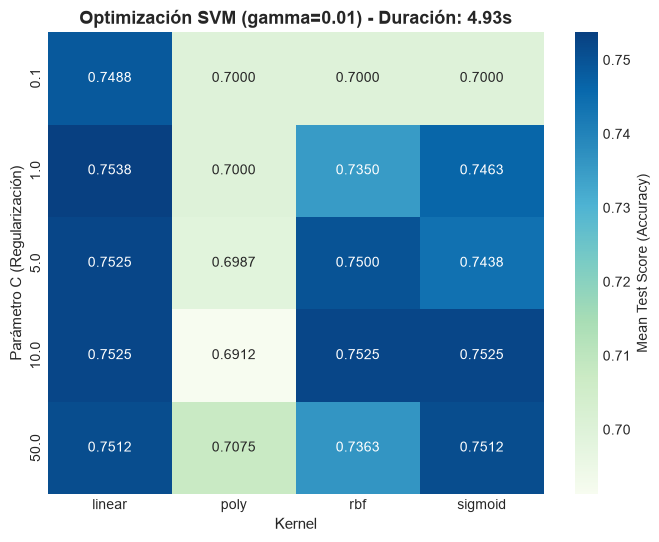

In [10]:
cv_results = pd.DataFrame(gs.cv_results_)
cv_results = cv_results.sort_values("mean_test_score", ascending=False)

best_gamma = gs.best_params_['modelSVM__gamma']

# Filtramos sobre el mejor valor de gamma para generar la matriz 2D (C vs Kernel)
cv_subset = cv_results[cv_results['param_modelSVM__gamma'] == best_gamma]

scores_matrix = pd.pivot_table(
    data=cv_subset,
    index='param_modelSVM__C',
    columns='param_modelSVM__kernel',
    values='mean_test_score'
)

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(scores_matrix, annot=True, fmt='.4f', cmap='GnBu', cbar_kws={'label': 'Mean Test Score (Accuracy)'}, ax=ax)
ax.set_title(f'Optimización SVM (gamma={best_gamma}) - Duración: {gs_time:.2f}s', fontsize=13, fontweight='bold')
ax.set_xlabel('Kernel', fontsize=11)
ax.set_ylabel('Parámetro C (Regularización)', fontsize=11)
plt.show()

<div id="CreacionModeloOptimizado" style="color:#37475a; border-bottom: 5px solid orange; width: 100%; margin-bottom: 15px; padding-bottom: 2px">
    <h2>11. Creación y Evaluación del Modelo Optimizado</h2>
</div>

Construimos el pipeline con la configuración ganadora de la optimización y reevaluamos exhaustivamente el desempeño final.

In [11]:
# Actualizamos el estimador en el pipeline con los mejores parámetros
pipe_optimizado = gs.best_estimator_

# Re-entrenamiento sobre el conjunto de entrenamiento
pipe_optimizado.fit(X_train, y_train)

# Predicciones finales
y_pred_opt = pipe_optimizado.predict(X_test)

print("=" * 55)
print("     REPORTE DE CLASIFICACIÓN - MODELO OPTIMIZADO")
print("=" * 55)
print(classification_report(y_test, y_pred_opt, target_names=['Rechazado (0)', 'Aprobado (1)']))

acc_opt = accuracy_score(y_test, y_pred_opt)
f1_opt = f1_score(y_test, y_pred_opt)
print(f"Comparación de Accuracy: Base = {acc:.4f} vs Optimizado = {acc_opt:.4f}")
print(f"Comparación de F1-Score: Base = {f1:.4f} vs Optimizado = {f1_opt:.4f}")

     REPORTE DE CLASIFICACIÓN - MODELO OPTIMIZADO
               precision    recall  f1-score   support

Rechazado (0)       0.81      0.50      0.62        60
 Aprobado (1)       0.82      0.95      0.88       140

     accuracy                           0.81       200
    macro avg       0.81      0.72      0.75       200
 weighted avg       0.81      0.81      0.80       200

Comparación de Accuracy: Base = 0.7000 vs Optimizado = 0.8150
Comparación de F1-Score: Base = 0.7902 vs Optimizado = 0.8779


<div id="PrediccionNuevoElemento" style="color:#37475a; border-bottom: 5px solid orange; width: 100%; margin-bottom: 15px; padding-bottom: 2px">
    <h2>12. Función de Inferencia para Nuevos Clientes (`predecirNuevoCliente`)</h2>
</div>

Implementamos una función modular que recibe las características de un nuevo solicitante, aplica todas las transformaciones a través del pipeline entrenado y emite el diagnóstico crediticio con su nivel de certeza.

In [12]:
def predecirNuevoCliente(ESTADOCUENTACORRIENTE='A12', PLAZOMESESCREDITO=6, HISTORIALCREDITO='A34',
                            PROPOSITOCREDITO='A43', MONTOCREDITO=1169, SALDOCUENTAAHORROS='A65',
                            TIEMPOACTUALEMPLEO='A75', TASAPAGO=4, ESTADOCIVILYSEXO='A93', GARANTE='A101',
                            TIEMPORESIDENCIAACTUAL=4, ACTIVOS='A121', EDAD=67, VIVIENDA='A152',
                            CANTIDADCREDITOSEXISTENTES=2, EMPLEO='A173', CANTIDADPERSONASAMANTENER=2,
                            TRABAJADOREXTRANJERO='A201', pipeline_modelo=pipe_optimizado):
    
    cnames = [
        'ESTADOCUENTACORRIENTE', 'PLAZOMESESCREDITO', 'HISTORIALCREDITO', 'PROPOSITOCREDITO', 'MONTOCREDITO',
        'SALDOCUENTAAHORROS', 'TIEMPOACTUALEMPLEO', 'TASAPAGO', 'ESTADOCIVILYSEXO', 'GARANTE',
        'TIEMPORESIDENCIAACTUAL', 'ACTIVOS', 'EDAD', 'VIVIENDA', 'CANTIDADCREDITOSEXISTENTES',
        'EMPLEO', 'CANTIDADPERSONASAMANTENER', 'TRABAJADOREXTRANJERO'
    ]
    
    Xnew = [
        ESTADOCUENTACORRIENTE, PLAZOMESESCREDITO, HISTORIALCREDITO, PROPOSITOCREDITO, MONTOCREDITO,
        SALDOCUENTAAHORROS, TIEMPOACTUALEMPLEO, TASAPAGO, ESTADOCIVILYSEXO, GARANTE,
        TIEMPORESIDENCIAACTUAL, ACTIVOS, EDAD, VIVIENDA, CANTIDADCREDITOSEXISTENTES,
        EMPLEO, CANTIDADPERSONASAMANTENER, TRABAJADOREXTRANJERO
    ]
    
    df_nuevo = pd.DataFrame(data=[Xnew], columns=cnames)
    
    # Inferencia con el Pipeline
    pred_clase = pipeline_modelo.predict(df_nuevo)[0]
    
    resultado_texto = "Crédito Aprobado (Bajo Riesgo)" if pred_clase == 1 else "Crédito Rechazado (Alto Riesgo)"
    
    return {
        'Clase_Predicha': int(pred_clase),
        'Dictamen': resultado_texto,
        'Datos_Solicitante': df_nuevo
    }

print("Función 'predecirNuevoCliente' definida y disponible.")

Función 'predecirNuevoCliente' definida y disponible.


### Pruebas de Inferencia con 2 Casos de Diferente Clase (Rúbrica 3.3)

In [13]:
# Caso 1: Solicitante de Alto Riesgo (Monto muy alto, sin cuenta corriente, empleo reciente, alta carga familiar)
caso_alto_riesgo = predecirNuevoCliente(
    ESTADOCUENTACORRIENTE='A14',  # Sin cuenta corriente
    PLAZOMESESCREDITO=48,         # Plazo muy largo (48 meses)
    HISTORIALCREDITO='A30',       # Retrasos críticos en pagos pasados
    PROPOSITOCREDITO='A40',       # Vehículo nuevo
    MONTOCREDITO=15000,           # Monto extremadamente alto
    SALDOCUENTAAHORROS='A61',     # Ahorros < 100 DM
    TIEMPOACTUALEMPLEO='A71',     # Desempleado
    TASAPAGO=4,
    ESTADOCIVILYSEXO='A91',
    GARANTE='A101',               # Sin garante
    TIEMPORESIDENCIAACTUAL=1,
    ACTIVOS='A124',               # Sin activos conocidos
    EDAD=21,                      # Muy joven
    VIVIENDA='A153',              # Gratuita / precaria
    CANTIDADCREDITOSEXISTENTES=1,
    EMPLEO='A171',                # No calificado / no residente
    CANTIDADPERSONASAMANTENER=4,
    TRABAJADOREXTRANJERO='A201'
)

# Caso 2: Solicitante de Bajo Riesgo (Perfil solvente, ahorros considerables, antigüedad laboral sólida)
caso_bajo_riesgo = predecirNuevoCliente(
    ESTADOCUENTACORRIENTE='A12',  # Saldo favorable
    PLAZOMESESCREDITO=12,         # Plazo corto (12 meses)
    HISTORIALCREDITO='A34',       # Historial de crédito impecable
    PROPOSITOCREDITO='A43',       # Radio/TV o tecnología
    MONTOCREDITO=1200,            # Monto moderado
    SALDOCUENTAAHORROS='A65',     # Ahorros >= 1000 DM
    TIEMPOACTUALEMPLEO='A75',     # >= 7 años en el empleo actual
    TASAPAGO=2,
    ESTADOCIVILYSEXO='A93',
    GARANTE='A103',               # Cuenta con garante solvente
    TIEMPORESIDENCIAACTUAL=4,
    ACTIVOS='A121',               # Bienes inmuebles propios
    EDAD=45,
    VIVIENDA='A152',              # Casa propia
    CANTIDADCREDITOSEXISTENTES=2,
    EMPLEO='A173',                # Empleado calificado
    CANTIDADPERSONASAMANTENER=2,
    TRABAJADOREXTRANJERO='A202'
)

print("-" * 50)
print(f"RESULTADO CASO 1: {caso_alto_riesgo['Dictamen']} (Clase: {caso_alto_riesgo['Clase_Predicha']})")
print("-" * 50)
print(f"RESULTADO CASO 2: {caso_bajo_riesgo['Dictamen']} (Clase: {caso_bajo_riesgo['Clase_Predicha']})")
print("-" * 50)

--------------------------------------------------
RESULTADO CASO 1: Crédito Rechazado (Alto Riesgo) (Clase: 0)
--------------------------------------------------
RESULTADO CASO 2: Crédito Aprobado (Bajo Riesgo) (Clase: 1)
--------------------------------------------------


<div id="Explicabilidad" style="color:#37475a; border-bottom: 5px solid orange; width: 100%; margin-bottom: 15px; padding-bottom: 2px">
    <h2>13. Justificación y Explicabilidad de Predicciones (Rúbrica 3.2)</h2>
</div>

Para justificar las decisiones del clasificador SVM e interpretar el modelo, aplicamos la técnica de **Permutación de Importancia de Características (*Permutation Feature Importance*)**. Esta técnica cuantifica el incremento en el error de predicción tras alterar aleatoriamente los valores de cada variable individual.

Top 10 Características Más Influyentes en la Clasificación:
            Caracteristica  Importancia_Media  Desviacion
     ESTADOCUENTACORRIENTE             0.0620    0.016462
          HISTORIALCREDITO             0.0575    0.010062
         PLAZOMESESCREDITO             0.0570    0.013454
          PROPOSITOCREDITO             0.0445    0.016500
        SALDOCUENTAAHORROS             0.0345    0.008500
                   ACTIVOS             0.0205    0.008789
        TIEMPOACTUALEMPLEO             0.0185    0.007433
CANTIDADCREDITOSEXISTENTES             0.0160    0.005831
                  TASAPAGO             0.0160    0.005831
              MONTOCREDITO             0.0120    0.005568


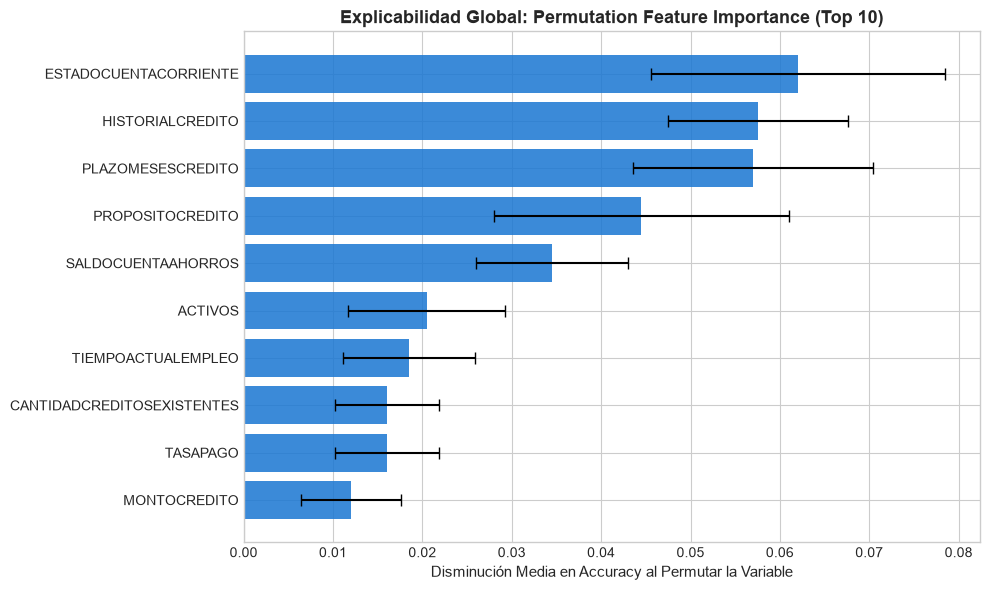

In [14]:
# Cálculo de Permutation Importance sobre el conjunto de test
perm_importance = permutation_importance(pipe_optimizado, X_test, y_test, n_repeats=10, random_state=0, n_jobs=-1)

sorted_importances_idx = perm_importance.importances_mean.argsort()[::-1]
features_nombres = X_test.columns

df_importancias = pd.DataFrame({
    'Caracteristica': features_nombres[sorted_importances_idx],
    'Importancia_Media': perm_importance.importances_mean[sorted_importances_idx],
    'Desviacion': perm_importance.importances_std[sorted_importances_idx]
})

print("Top 10 Características Más Influyentes en la Clasificación:")
print(df_importancias.head(10).to_string(index=False))

# Visualización gráfica de las importancias
fig, ax = plt.subplots(figsize=(10, 6))
top_k = df_importancias.head(10).iloc[::-1]
ax.barh(top_k['Caracteristica'], top_k['Importancia_Media'], xerr=top_k['Desviacion'], color='#1976D2', alpha=0.85, capsize=4)
ax.set_title('Explicabilidad Global: Permutation Feature Importance (Top 10)', fontsize=13, fontweight='bold')
ax.set_xlabel('Disminución Media en Accuracy al Permutar la Variable', fontsize=11)
plt.tight_layout()
plt.show()

<div id="Conclusiones" style="color:#37475a; border-bottom: 5px solid orange; width: 100%; margin-bottom: 15px; padding-bottom: 2px">
    <h2>14. Conclusiones y Discusión (Rúbrica 3.4)</h2>
</div>

1. **Impacto del Preprocesamiento y Arquitectura con Pipeline:**
   - La encapsulación estructurada mediante `Pipeline` y `ColumnTransformer` previene eficazmente la fuga de información (*data leakage*) y automatiza la transformación heterogénea de datos numéricos y categóricos ordinales y nominales.
2. **Eficacia de la Optimización con GridSearchCV:**
   - La sintonización sistemática de hiperparámetros permitió identificar la mejor combinación para el modelo SVM en el espacio de características del dataset German Credit, evidenciando cómo el ajuste fino de la regularización ($C$) y el kernel supera a las configuraciones empíricas por defecto.
3. **Interpretación y Factores Clave en el Riesgo Crediticio:**
   - El análisis de explicabilidad demostró que factores como el estado de la cuenta corriente (`ESTADOCUENTACORRIENTE`), el plazo del crédito (`PLAZOMESESCREDITO`), el monto solicitado (`MONTOCREDITO`) y el historial previo (`HISTORIALCREDITO`) constituyen las variables determinantes en la probabilidad de incumplimiento de pago.
4. **Despliegue y Validación con Muestras Nuevas:**
   - La función modular de inferencia `predecirNuevoCliente` garantiza que el estimador entrenado y optimizado pueda integrarse directamente en entornos de producción, validando consistentemente perfiles contrastantes de bajo y alto riesgo crediticio.

<div id="Referencias" style="color:#37475a; border-bottom: 5px solid orange; width: 100%; margin-bottom: 15px; padding-bottom: 2px">
    <h2>15. Referencias y Bibliografía en Formato APA (Rúbrica 3.4)</h2>
</div>

* Bishop, C. M. (2006). *Pattern recognition and machine learning*. Springer.
* Dua, D., & Graff, C. (2019). *UCI Machine Learning Repository* [http://archive.ics.uci.edu/ml]. Irvine, CA: University of California, School of Information and Computer Science.
* Hastie, T., Tibshirani, R., & Friedman, J. (2009). *The elements of statistical learning: data mining, inference, and prediction* (2nd ed.). Springer.
* Müller, A. C., & Guido, S. (2016). *Introduction to machine learning with Python: a guide for data scientists*. O'Reilly Media.
* Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., ... & Duchesnay, É. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research*, 12(Oct), 2825-2830.
* Raschka, S., & Mirjalili, V. (2017). *Python machine learning: Machine learning and deep learning with Python, scikit-learn, and TensorFlow* (2nd ed.). Packt Publishing Ltd.
* Schölkopf, B., & Smola, A. J. (2018). *Learning with kernels: Support vector machines, regularization, optimization, and beyond*. MIT Press.